In [31]:
import pandas as pd
disease_df=pd.read_csv("healthcare/framingham.csv")
print(f"{disease_df.shape}")
disease_df.tail()
# BPMeds: whether patient was on blood pressure medication
# prevalentStroke: whether patient had experienced a stroke 
# prevalentHyp: whether patient was hypertensive
# totChol: total cholesterol 
# sysBP: systolic blood pressure
# diaBP: diastolic blood pressure 
# BMI:body mass index: body fat based on height and weight
# glucose: blood sugar
# TenyearCHD: 10 year risk of Coronary heart disease --> target variabe

(4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0
4239,0,39,3.0,1,30.0,0.0,0,0,0,196.0,133.0,86.0,20.91,85.0,80.0,0


In [32]:
disease_df.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

TenYearCHD
0    3596
1     644
Name: count, dtype: int64

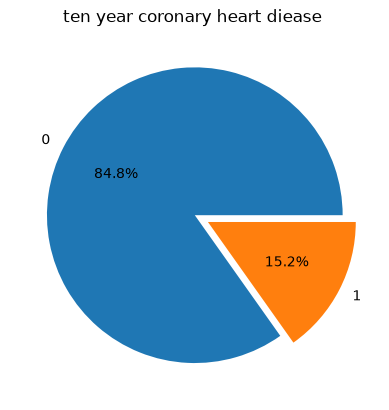

In [33]:
import matplotlib.pyplot as plt
ax=disease_df['TenYearCHD'].value_counts().plot.pie( autopct='%1.1f%%',explode=[0,0.1]) 
ax.set_title('ten year coronary heart diease ')
disease_df.TenYearCHD.value_counts()

In [34]:
disease_df=disease_df.drop(['education'],axis=1)
disease_df.rename(columns={'male':'Sex_male'},inplace=True)
disease_df=disease_df.dropna(axis=0)
disease_df.tail()


,Sex_male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4233,1,50,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4237,0,52,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0
4239,0,39,1,30.0,0.0,0,0,0,196.0,133.0,86.0,20.91,85.0,80.0,0


In [35]:
X=disease_df[['age', 'Sex_male', 'cigsPerDay', 'totChol', 'sysBP', 'glucose']]
print(f"{X.shape}")
X.tail()

(3751, 6)


,age,Sex_male,cigsPerDay,totChol,sysBP,glucose
4233,50,1,1.0,313.0,179.0,86.0
4234,51,1,43.0,207.0,126.5,68.0
4237,52,0,0.0,269.0,133.5,107.0
4238,40,1,0.0,185.0,141.0,72.0
4239,39,0,30.0,196.0,133.0,80.0


In [36]:
y=disease_df['TenYearCHD']
print(f"{y.shape}")
y.tail()

(3751,)


4233    1
4234    0
4237    0
4238    0
4239    0
Name: TenYearCHD, dtype: int64

In [37]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=4)
print(f"{X_train.shape}{X_test.shape}")

(2625, 6)(1126, 6)


In [38]:
X_test.tail()

,age,Sex_male,cigsPerDay,totChol,sysBP,glucose
1367,53,0,0.0,272.0,146.0,67.0
3442,62,1,20.0,263.0,112.0,95.0
87,61,0,1.0,326.0,200.0,78.0
3976,56,0,0.0,287.0,169.0,83.0
442,43,0,20.0,265.0,107.0,95.0


In [39]:
from sklearn import preprocessing
scaler=preprocessing.StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


              precision    recall  f1-score   support

           0       0.85      0.99      0.92       951
           1       0.61      0.08      0.14       175

    accuracy                           0.85      1126
   macro avg       0.73      0.54      0.53      1126
weighted avg       0.82      0.85      0.80      1126



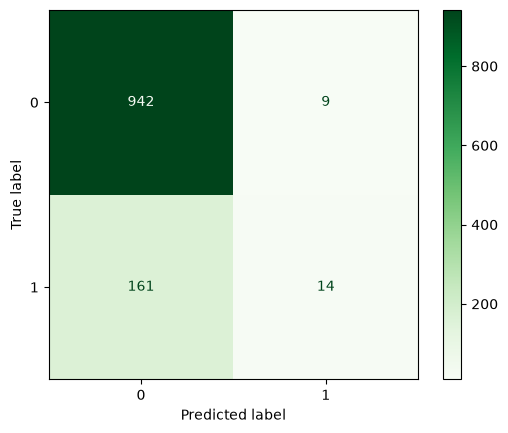

In [46]:
from sklearn.linear_model import LogisticRegression
reg=LogisticRegression()
reg.fit(X_train,y_train)
y_pred=reg.predict(X_test)

from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay
print(classification_report(y_test,y_pred))
cm=confusion_matrix(y_test,y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
# row: true, column: predict
disp.plot(cmap=plt.cm.Greens)